# Frozen seven-variable forest: prediction importance and cross-network physical consistency

Dedicated analysis, 19 October 2026. **These results reconstruct the final tuned seven-input forests**, not the historical relative-sweep forests. The baseline and historical output directory are unchanged. Only the 2,170 baseline partial-collapse comparisons across 15 networks are included. Whole-network single-centerline cases remain a separate transfer evaluation.

The strongest learned associations recur across networks, but they do not establish universal physical laws. Mean width ratio and parent size dominate the frozen forest: equal-network mean absolute SHAP is **6.54 and 5.39 minutes**, followed by mean-length ratio (**0.70**) and entropy ratio (**0.54**). Width and size are the top two in every network. Permuting either worsens both loss metrics in **15/15 networks**: relative-loss increases are **157.77 and 76.52 percentage points**, with substantial network SDs of **98.20 and 48.35 pp**. Mean-length ratio helps relative loss in 14/15 networks but squared error in only 12/15; entropy helps in 13/15 and 10/15. Small-variable importance is not uniformly beneficial.

Signed SHAP dependence is negative for width ratio and parent size in 15/15 networks, and positive for mean-length and entropy ratios in 15/15. These suggest that the fitted models associate larger width ratios with advances and larger length ratios with delays or smaller advances, with scale-dependent behavior. This is qualitatively compatible with a geometry/travel-time interpretation, but the full centroid also depends on hydrograph redistribution and the analysis does not isolate a causal mechanism.

**Parent size is the main warning against reading marginal correlations as model effects:** pooled response rho is **+0.570**, whereas the equal-network mean within-network rho is **+0.008** (9 positive, 6 negative), while signed SHAP dependence is negative in all 15. Width–size interaction allocation is large: equal-network mean absolute pair SHAP **7.07 minutes**, range **1.56–23.28** across networks. Between-network composition and interactions are plausible explanations for the discrepancy; this is not proof that increasing size causes an advance. Width CV also disagrees: its response correlation is positive in all 15 networks, but SHAP dependence is negative in 14/15 and its importance is tiny. Redundant geometric information can produce such differences.

Summary exclusions preserve the same forests. Removing 54 changes relative error **63.74% → 60.04%**, while removing the extreme 37 case barely changes it (**63.73%**) but increases R² **0.6145 → 0.7134**. The latter is squared-error sensitivity, not evidence of a different learned physical mechanism. All importance, correlation and ALE summaries are saved for these exclusions and for excluding both. No training-influence refit or predictor change was performed.

ALE broadly supports the principal directions: eight-bin endpoint contrasts are negative for width in **15/15 networks**, positive for mean length, length SD and entropy in **15/15**, and negative for width CV in **15/15**. Parent-size contrasts are negative in **12 of 13 networks with complete bin support**, with one zero contrast; two networks have empty bins and are omitted from that directional summary. Dominance is small and non-monotonic, with six positive and four negative contrasts among eleven supported curves (one zero). Endpoint signs do not mean every local bin is monotonic. The broad aggregate shapes persist across 4, 8 and 12 bins, but parent size’s highest eight-bin interval has only **three contributing networks**.

Predictor redundancy recurs: width ratio versus entropy has mean within-network rho **−0.741** (negative in all 15), and width ratio versus mean length **−0.569** (negative in all 15). Permuting all seven inputs jointly increases relative loss by **127.06 pp**, less than width alone (**157.77 pp**). This supports caution about individual shuffles breaking coherent geometry; it is not evidence that removing other variables would improve the model.

The width–size pair allocation changes with scale: in the highest-width bin it averages about **+5.0 minutes** for the smallest-size bin, **−11.1 minutes** for the next-to-largest size bin, and **−39.2 minutes** for the largest-size bin. The last cell contains only **nine comparisons from four networks**, and its size range is broad (21.85–102.57 km). This supports a scale-dependent learned association, with limited evidence at the largest sizes, not a universal multiplicative law. Network 22 has **83.6%** of held comparisons above its training fold’s parent-size maximum, another reason to qualify the tail.

The importance ordering is unchanged in all four summary views. Excluding the extreme case changes the two leading mean absolute SHAP values by less than **0.006 minutes**; excluding 54 leaves width and size dominant (**6.73 and 5.51 minutes**). These summary rankings are stable even though squared-error performance is sensitive to the extreme case. Training-influence stability remains untested because no exclusion refits were requested.


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display
ROOT = Path.cwd()
while not (ROOT / 'RAPID').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run inside river-hierarchy')
    ROOT = ROOT.parent
OUT = ROOT / 'RAPID/outputs/hydrograph_frozen_interpretation_20261019'

## Provenance and verification

Exact settings, seven-column order, seed 20261014, training-network weights, fold-fitted preprocessing and target scaling are inherited from `drop_exposure_check.py`. SHA256 hashes and package versions are in `design.json`. The baseline prediction table is filtered to `seven_inputs` and joined one-to-one by network/state. Each network is excluded completely from its training fold. Settings were previously selected using these networks; this is exploratory fixed-setting interpretation, not fresh nested validation.

SHAP uses exact tree-path-dependent TreeSHAP, explaining the held-network prediction relative to each forest’s own weighted training-path baseline. Additivity of both SHAP and the interaction decomposition is checked numerically in minutes. Fold baselines differ. The 2,170 comparisons are **not 2,170 independent network samples**; all aggregate importance summaries give networks equal weight.

In [2]:
table = pd.read_csv(OUT / 'verification.csv')
table = table[['example', 'prediction_max_error_minutes', 'shap_additivity_max_error_minutes', 'interaction_additivity_max_error_minutes']]
display(table)

example,prediction_max_error_minutes,shap_additivity_max_error_minutes,interaction_additivity_max_error_minutes
2,1.776e-15,9.415e-14,5.773e-14
3,1.776e-15,6.04e-14,6.04e-14
5,8.882e-16,5.773e-14,7.638e-14
13,7.105e-15,9.592e-14,8.171e-14
15,1.776e-15,2.416e-13,1.368e-13
21,1.776e-15,5.507e-14,7.638e-14
22,8.882e-15,2.842e-13,4.192e-13
37,3.553e-15,1.066e-13,1.812e-13
41,7.105e-15,4.121e-13,2.132e-13
45,3.553e-15,1.315e-13,7.994e-14


## Held-network permutation importance

Twenty repeats per network, identical shuffle orders across groups for paired comparison. Group members share one row permutation. Relative loss is 100 × |prediction−response| / max(|response|, 1 minute). Positive changes mean disrupted information helped prediction. Squared-error changes are in minutes². R² decrease divides the equal-network MSE increase by the fixed equal-network response variance for that view; it is not a mean of network R² values.

Groups: length geometry = mean-length ratio, parent size, length-SD ratio; width geometry = mean-width and width-CV ratios; branching = entropy ratio and parent dominance; width–entropy = both width ratios and entropy ratio; length–width = all length and width variables. Joint shuffling preserves dependence within a group but breaks its dependence with other inputs. Importance is not additive, and individual permutations may generate physically implausible combinations. Within-network permutation cannot evaluate network-constant information.

Network SD/min/max describe heterogeneity, not confidence intervals. Shuffle Monte Carlo SD describes finite-repeat randomness, not uncertainty across populations of networks.

In [3]:
table = pd.read_csv(OUT / 'permutation_summary.csv')
table = table.query("view == 'all'")
table = table[['group', 'delta_relative_pp', 'delta_relative_pp_sd', 'delta_relative_pp_min', 'delta_relative_pp_max', 'delta_relative_pp_positive_networks', 'delta_mse_minutes2', 'r2_decrease', 'shuffle_mc_sd_relative_pp']]
display(table)

group,delta_relative_pp,delta_relative_pp_sd,delta_relative_pp_min,delta_relative_pp_max,delta_relative_pp_positive_networks,delta_mse_minutes2,r2_decrease,shuffle_mc_sd_relative_pp
B_parent_dominance_mean,0.1563,0.9482,-1.686,2.467,9,0.06659,0.0005061,0.1774
all_inputs,127.1,66.51,34.01,283.5,15,131.8,1.002,4.855
branching,5.955,7.11,-5.223,20.17,14,0.857,0.006514,0.7604
domain_size,76.52,48.35,8.526,168.6,15,102,0.7755,4.145
length_geometry,77.39,42.7,13.97,157.7,15,83.65,0.6358,3.477
length_width,116.1,58.97,32.31,243.8,15,122.5,0.9314,4.568
log1p__B_ratio_route_entropy,5.854,6.983,-5.576,19.51,13,0.7652,0.005816,0.7201
log1p__B_ratio_route_length_mean,14.19,14.81,-3.816,42.26,14,5.043,0.03833,0.7739
log1p__B_ratio_route_length_sd,1.973,2.044,-0.6115,6.371,14,0.3333,0.002533,0.404
log1p__B_ratio_width_cv,0.1642,1.31,-3.184,2.209,10,0.2995,0.002277,0.2293


## SHAP magnitude and cross-network stability

Mean absolute SHAP measures allocation of a prediction, not predictive gain, direction, causality or statistical significance. Correlated predictors can share allocations. Signed SHAP/value rank correlations summarize a dependence cloud, not a controlled derivative. Inspect ALE alongside them. The rank range and network magnitude ranges show stability without treating comparisons as independent replicates.

In [4]:
table = pd.read_csv(OUT / 'shap_summary.csv')
table = table.query("view == 'all'")
display(table)

view,feature,mean_abs_shap_minutes,network_sd,network_min,network_max,median_rank,rank_min,rank_max,direction_rho_mean,direction_positive,direction_negative
all,B_parent_dominance_mean,0.1045,0.04465,0.03663,0.166,6,5,7,-0.3769,3,12
all,domain_size,5.389,3.209,2.464,12.73,2,1,2,-0.8491,0,15
all,log1p__B_ratio_route_entropy,0.5423,0.2858,0.2766,1.141,4,3,4,0.7678,15,0
all,log1p__B_ratio_route_length_mean,0.699,0.1713,0.4493,1.003,3,3,4,0.8719,15,0
all,log1p__B_ratio_route_length_sd,0.137,0.04669,0.09221,0.2723,6,5,6,0.6786,14,1
all,log1p__B_ratio_width_cv,0.08357,0.03401,0.03065,0.1577,7,5,7,-0.2394,1,14
all,log1p__B_ratio_width_mean,6.543,4.1,3.108,15.63,1,1,2,-0.8538,0,15


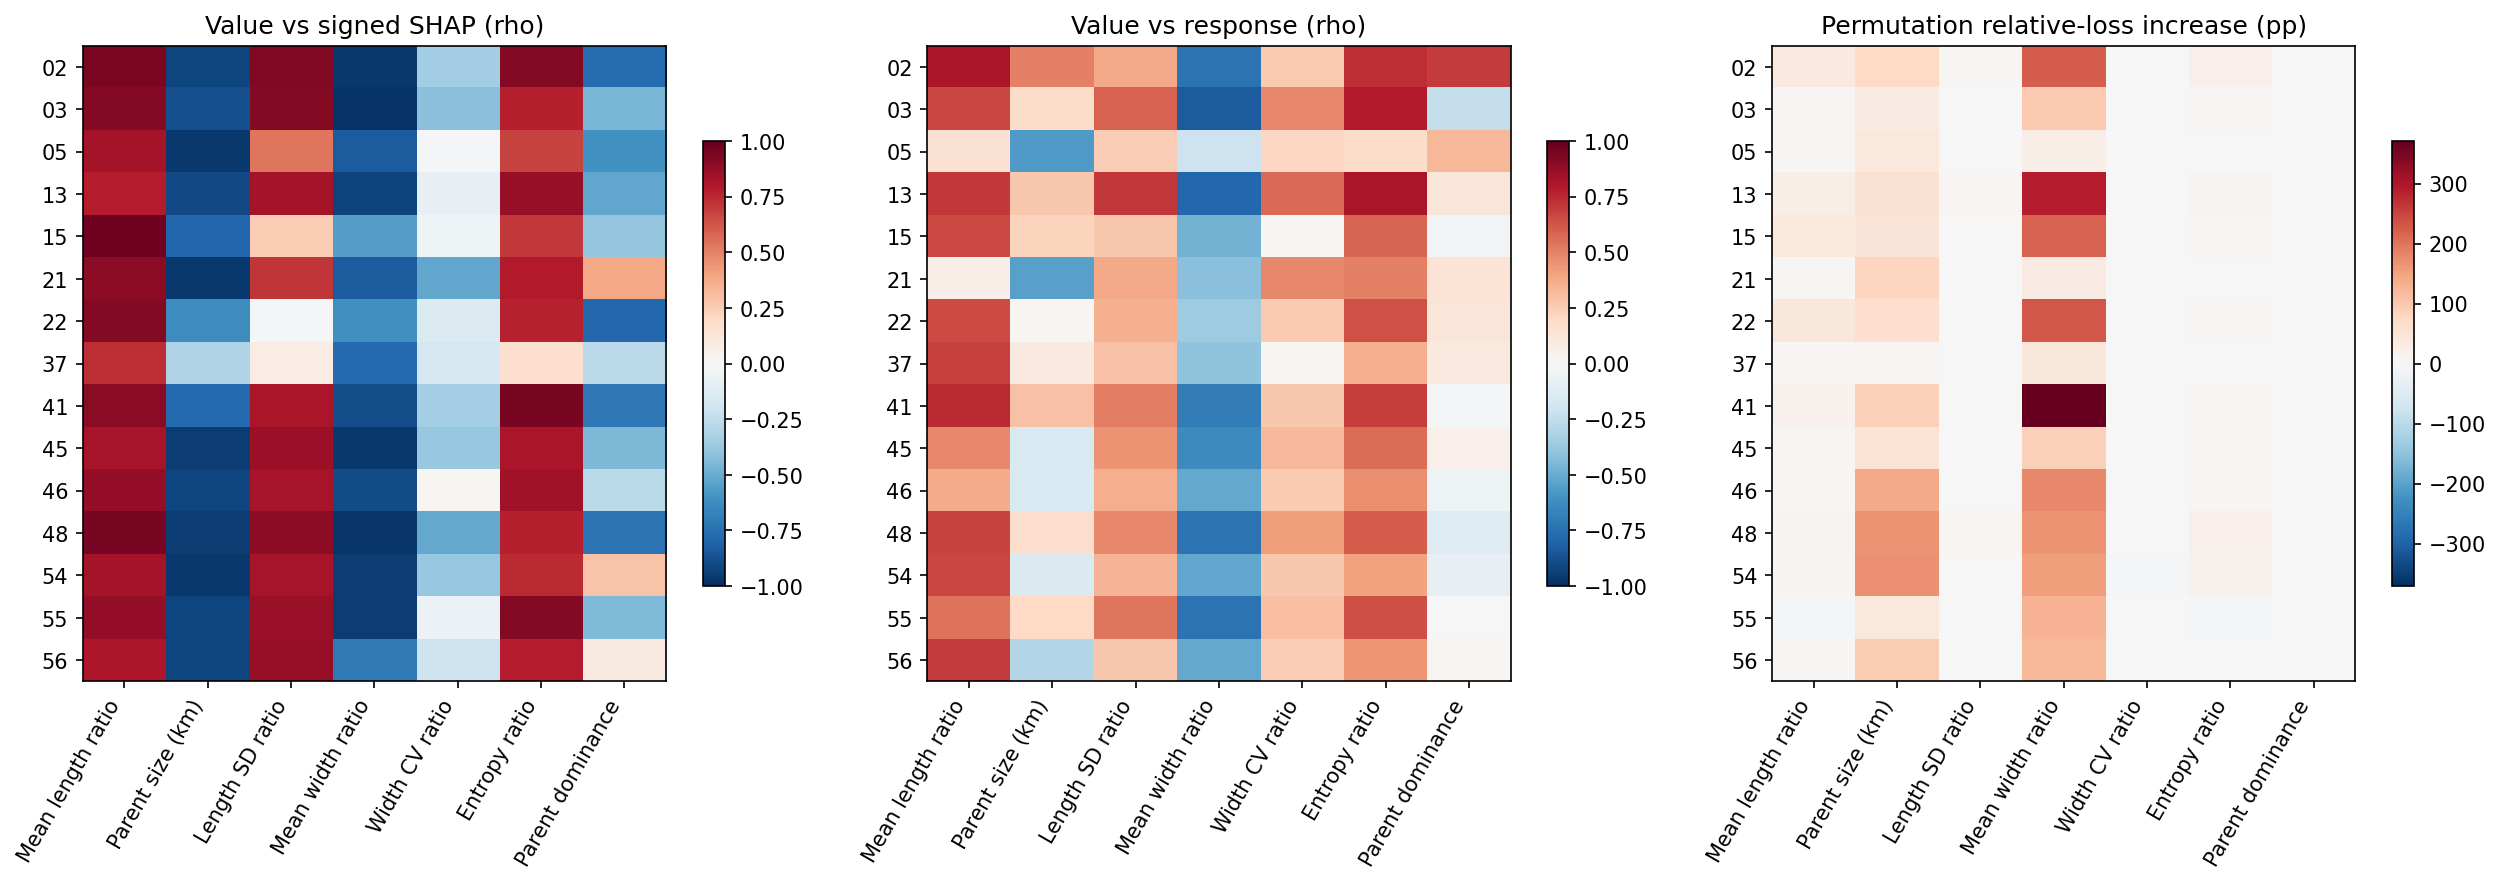

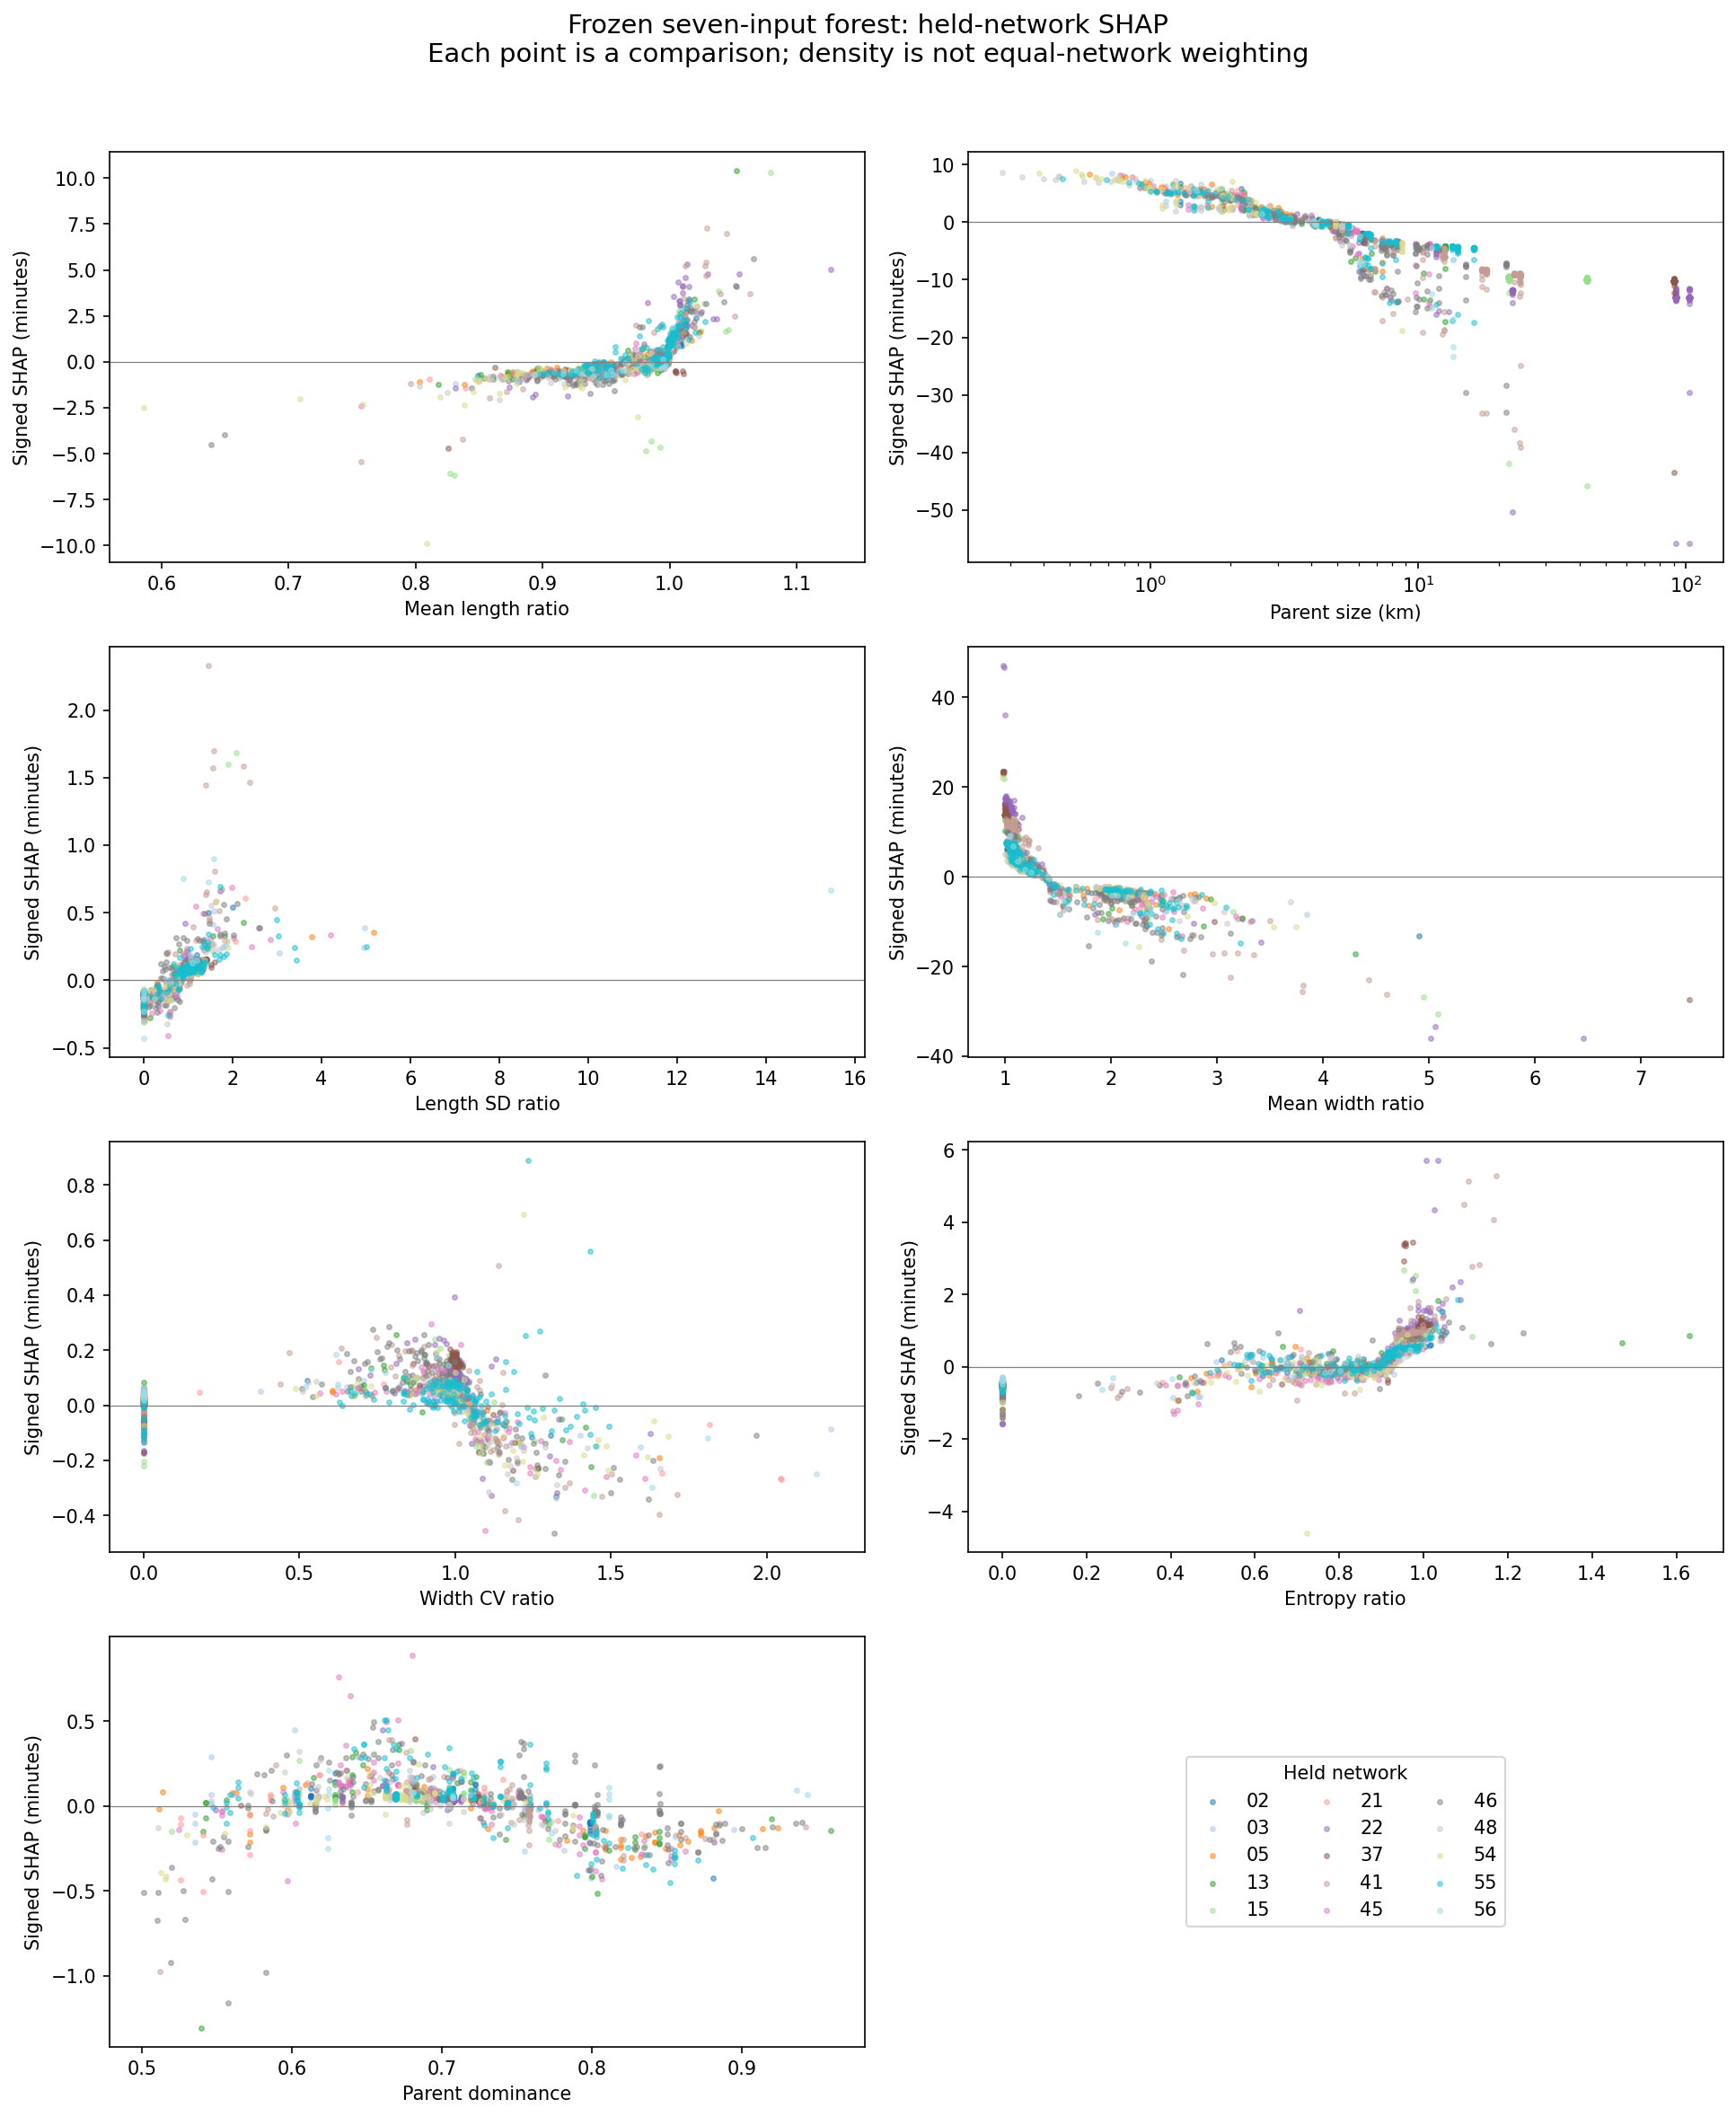

## Accumulated local effects and support

First-order ALE changes one transformed predictor between adjacent local bin boundaries, predicts each held-network row using its held-out forest, and averages local changes. Common boundaries are quantiles of the equal-network mixture of baseline inputs. Each supported network receives equal weight per bin; unsupported networks are omitted and explicitly counted. The accumulated curve is centered using equal-network bin frequencies. Thus this describes a collection of cross-fitted models, not one universal forest response function. Mid-bin values use half the bin’s local difference, the usual piecewise-linear display convention.

Gray curves use each network’s own eight quantile bins and centering; colored curves use 4, 8 and 12 common bins. Lines connect bin summaries, not mechanistic trajectories. Large bins and sparse joint support can still involve unrealistic perturbations; ALE reduces, but cannot remove, that problem. Feature axes show original ratios, while perturbations use the model’s ln(1+ratio) coordinates. Point annotations count contributing networks. `ale_local_differences.parquet`, `ale_summary.csv` and `support.csv` preserve exact boundaries, row counts, network counts, local-difference variability and held values beyond training ranges.

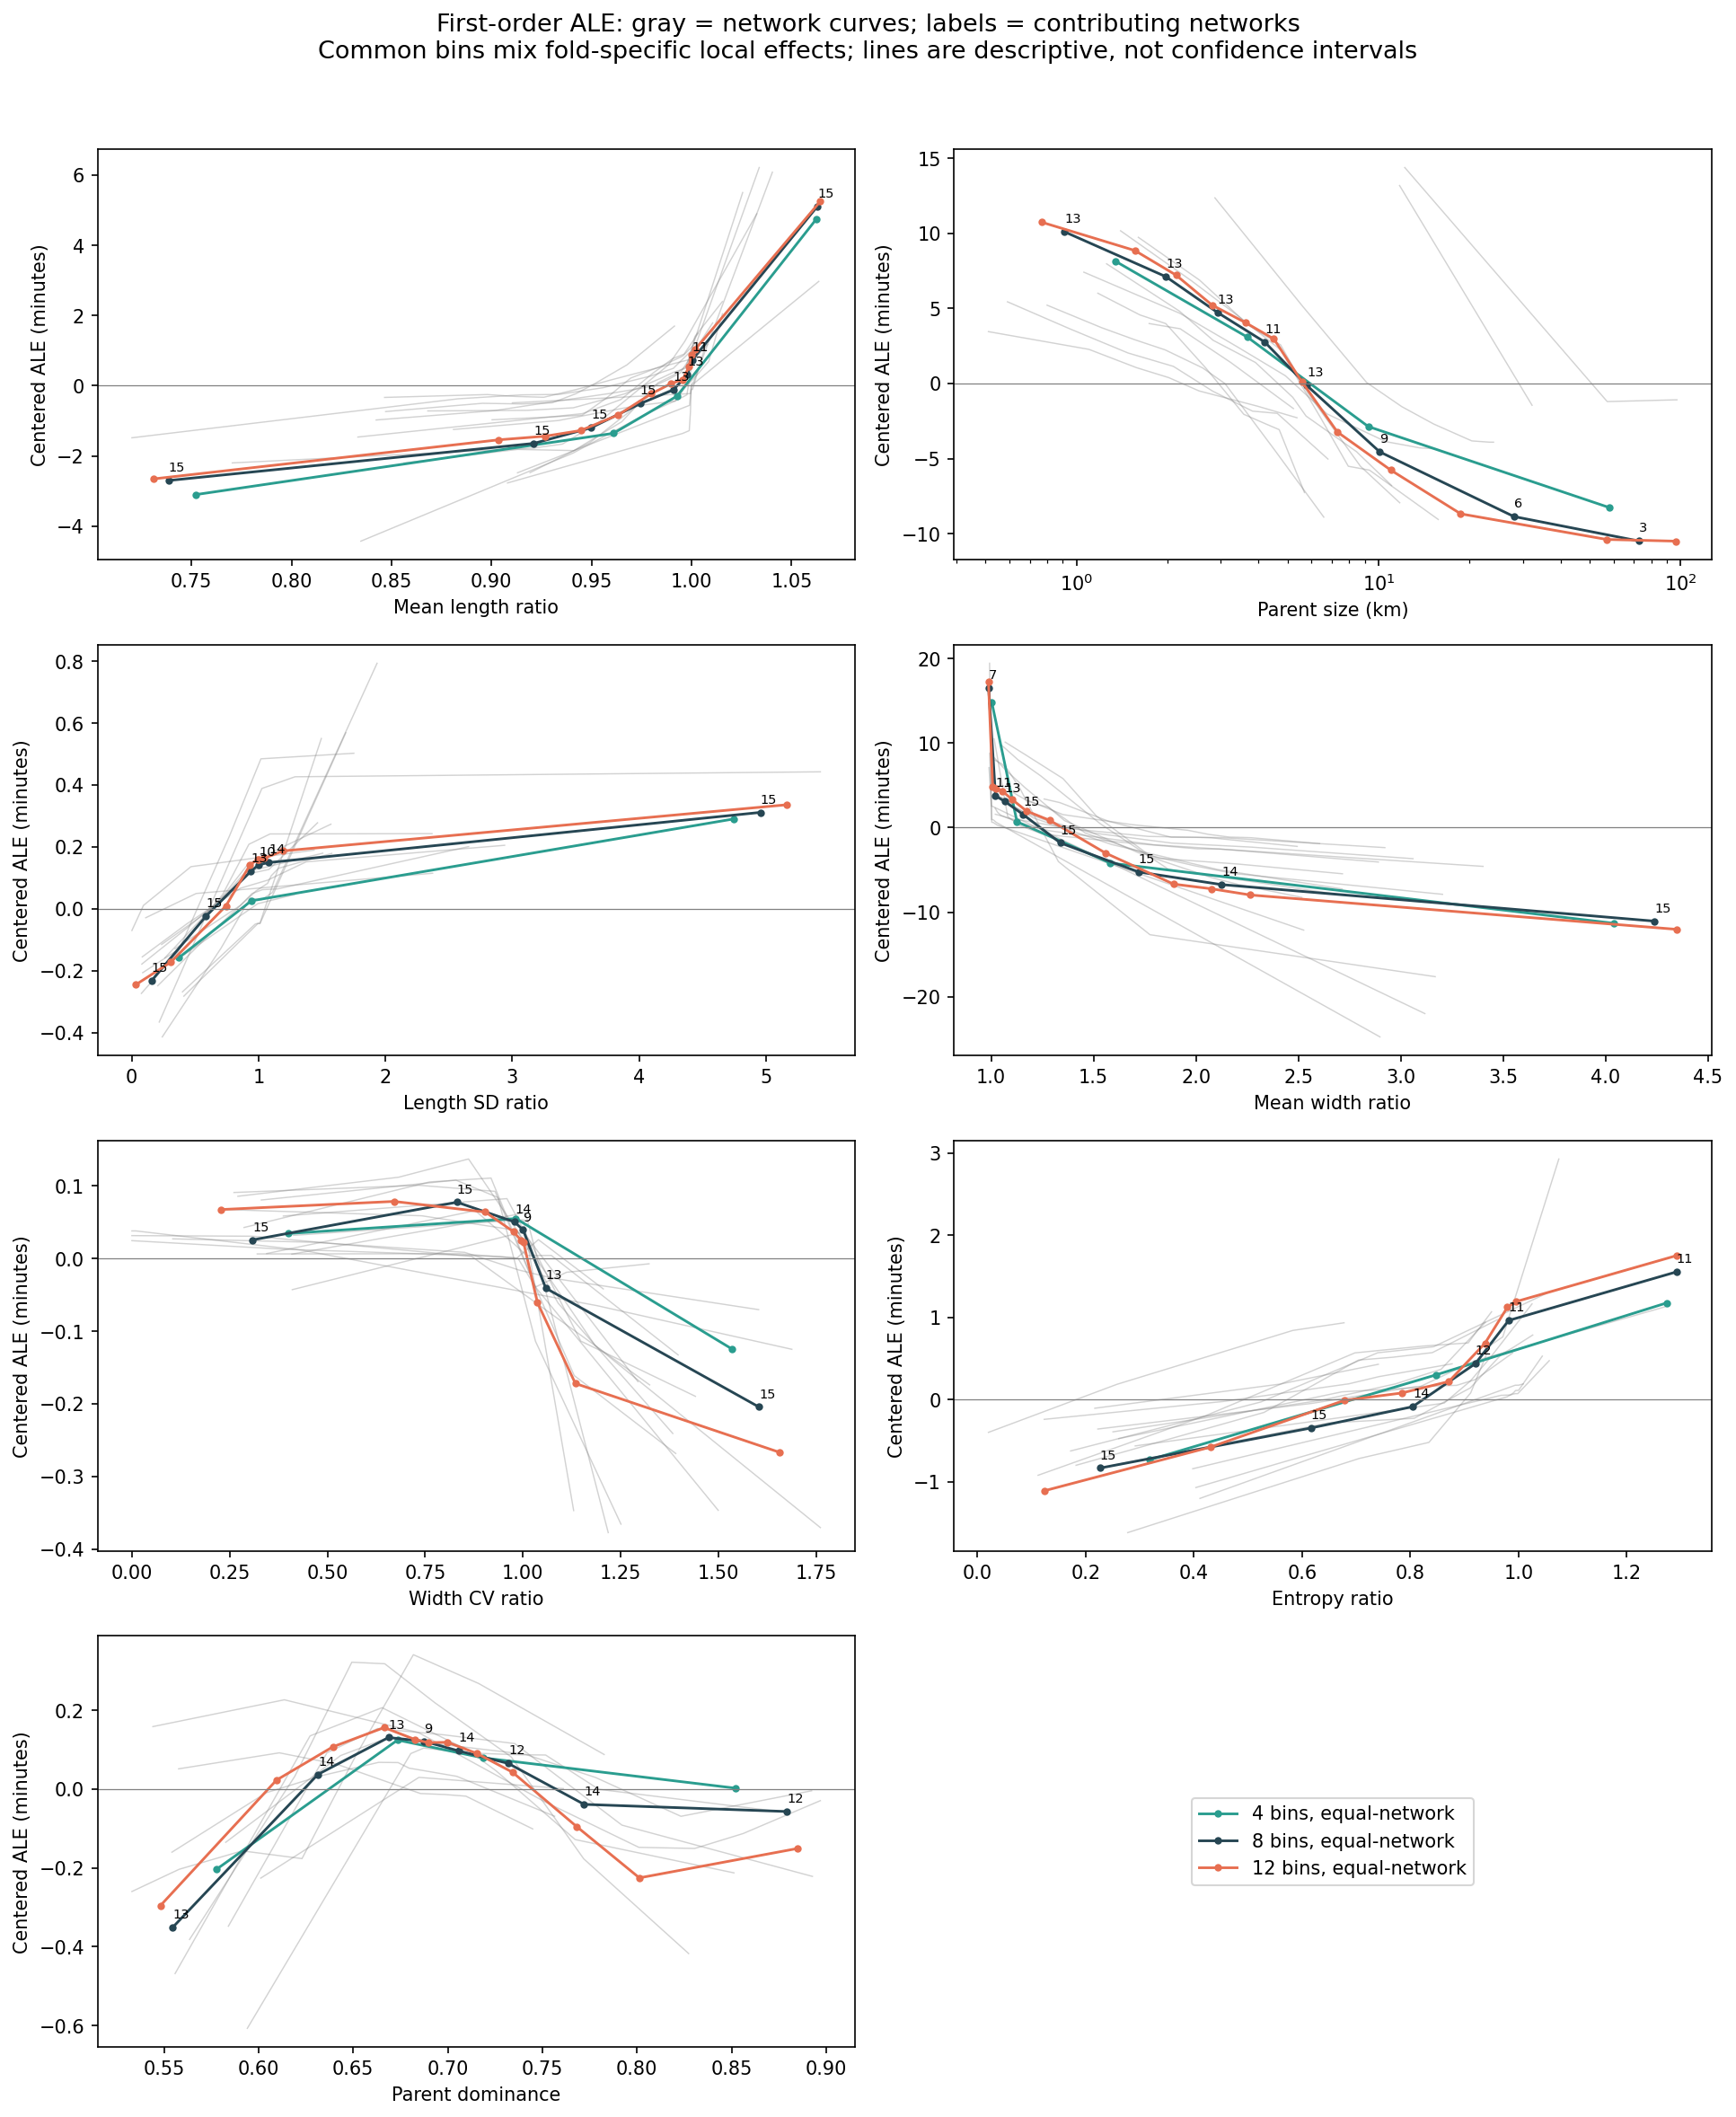

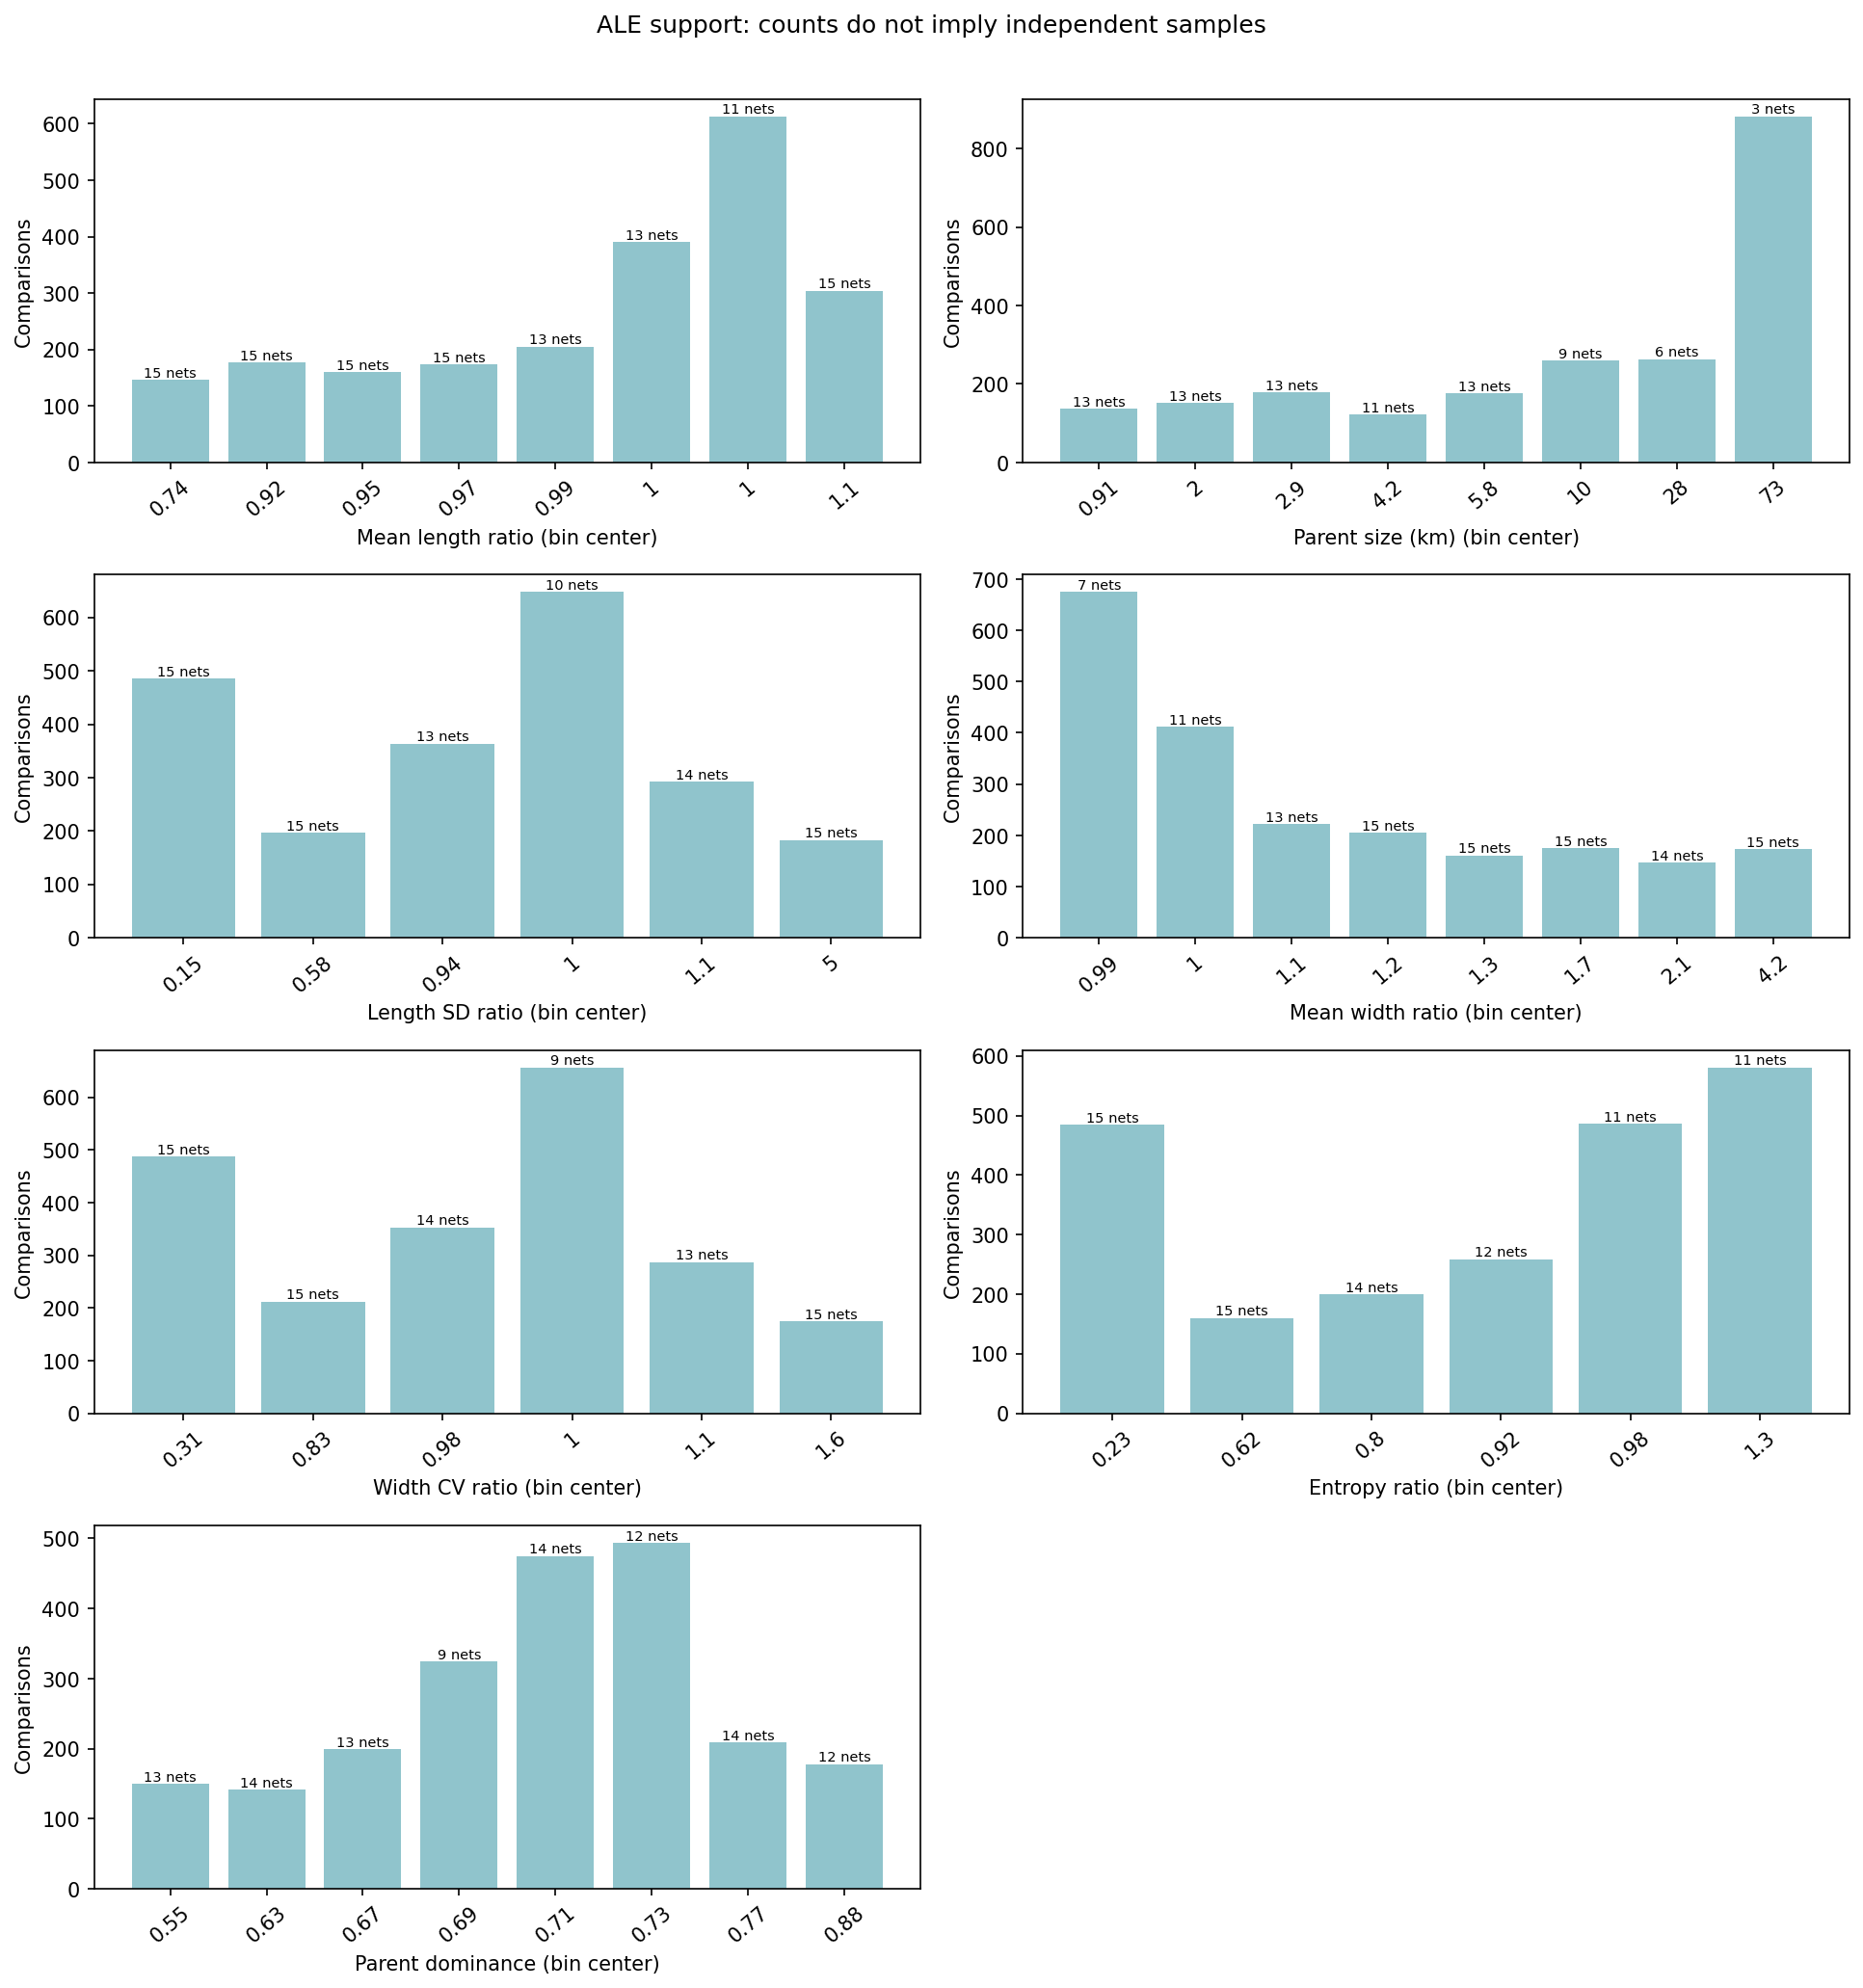

In [5]:
table = pd.read_csv(OUT / 'ale_direction_summary.csv')
table = table.query("view == 'all' and bins == 8")
display(table)

view,feature,bins,mean_endpoint_contrast_minutes,min_endpoint_contrast,max_endpoint_contrast,positive_networks,negative_networks,valid_networks
all,B_parent_dominance_mean,8,0.1231,-0.1878,0.5514,6,4,11
all,domain_size,8,-12.23,-19.22,0,0,12,13
all,log1p__B_ratio_route_entropy,8,1.619,0.5347,4.547,15,0,15
all,log1p__B_ratio_route_length_mean,8,4.393,1.096,10.64,15,0,15
all,log1p__B_ratio_route_length_sd,8,0.5207,0.1437,1.207,15,0,15
all,log1p__B_ratio_width_cv,8,-0.2523,-0.4564,-0.03187,0,15,15
all,log1p__B_ratio_width_mean,8,-15.78,-44.2,-3.949,0,15,15


Endpoint contrasts above compare the first and last supported mid-bin ALE values within each network’s own range; they are not a common physical contrast or proof of monotonicity. Bin-level positive/negative counts are saved in `ale_direction_by_network.csv`. Empty-bin exclusion curves are omitted from endpoint summaries rather than bridged.

## Width ratio × parent-size interaction

Pair values are twice the off-diagonal SHAP interaction entry, in minutes, preserving the full pair allocation. This is a decomposition of model predictions, not a physical interaction coefficient or a second-order ALE surface. The 5×5 joint table averages within each network then equally across contributing networks. Empty cells have no evidence; cells with few networks should not support broad physical claims. Exact ratio/size edges and counts are in `width_size_joint_support.csv`. A negative pair allocation means this pair pushes toward an advance relative to the SHAP decomposition, not that increasing width always advances the centroid.

In [6]:
table = pd.read_csv(OUT / 'interaction_summary.csv')
display(table)

view,mean_absolute_pair_minutes,sd,min,max
all,7.072,6.978,1.559,23.28
without54_summary,7.379,7.136,1.559,23.28
without_extreme_summary,7.069,6.973,1.559,23.28
without_both_summary,7.376,7.13,1.559,23.28


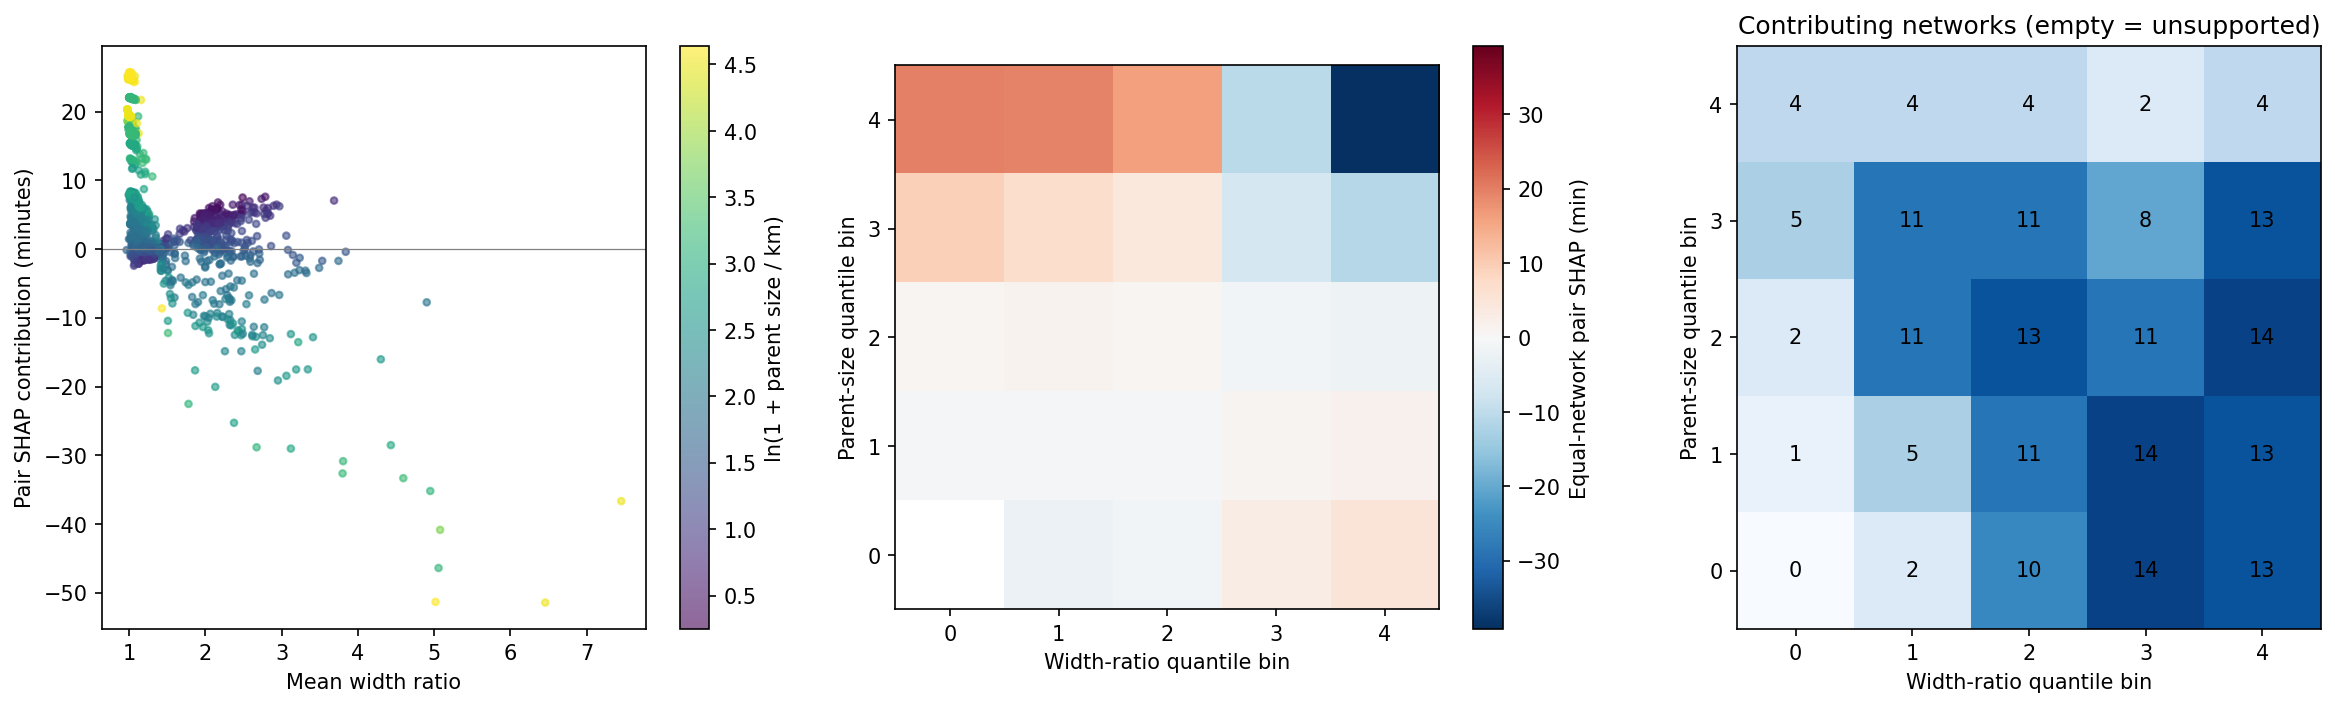

## Marginal correlations versus conditional model behavior

Pooled Spearman correlations use all rows and can be dominated by larger networks; they are shown deliberately as a comparison, not as the primary cross-network estimate. Primary summaries average within-network Spearman coefficients equally, with min/max and positive/negative counts. Near-constant variables (range < 1e−10), fewer than four observations or constant responses have undefined rho. No naive independent-row p-values are reported.

Disagreement between marginal response correlation, SHAP/value correlation and ALE may reflect predictor redundancy, between-network composition, nonlinearities and interactions, or residual confounding. SHAP allocates predictions relative to a baseline, whereas ALE makes local conditional model perturbations. Neither identifies a causal effect. The positive direction of a centroid shift is delay; negative is advance. Geometry alone does not establish a monotonic hydraulic law for the full excess-volume centroid.

In [7]:
table = pd.read_csv(OUT / 'response_correlation_summary.csv')
table = table.query("view == 'all'")
display(table)

view,feature,mean_within_rho,median_within_rho,min_rho,max_rho,valid_networks,positive,negative,pooled_row_rho
all,B_parent_dominance_mean,0.06988,0.02234,-0.2346,0.6979,15,8,7,0.03941
all,domain_size,0.007609,0.09869,-0.5629,0.5043,15,9,6,0.5698
all,log1p__B_ratio_route_entropy,0.5608,0.5825,0.1811,0.8138,15,15,0,0.7482
all,log1p__B_ratio_route_length_mean,0.573,0.6696,0.06563,0.8151,15,15,0,0.7048
all,log1p__B_ratio_route_length_sd,0.4122,0.3798,0.2478,0.7036,15,15,0,0.4832
all,log1p__B_ratio_width_cv,0.2922,0.2703,0.0116,0.5635,15,15,0,0.3305
all,log1p__B_ratio_width_mean,-0.5721,-0.5219,-0.8358,-0.206,15,0,15,-0.7409


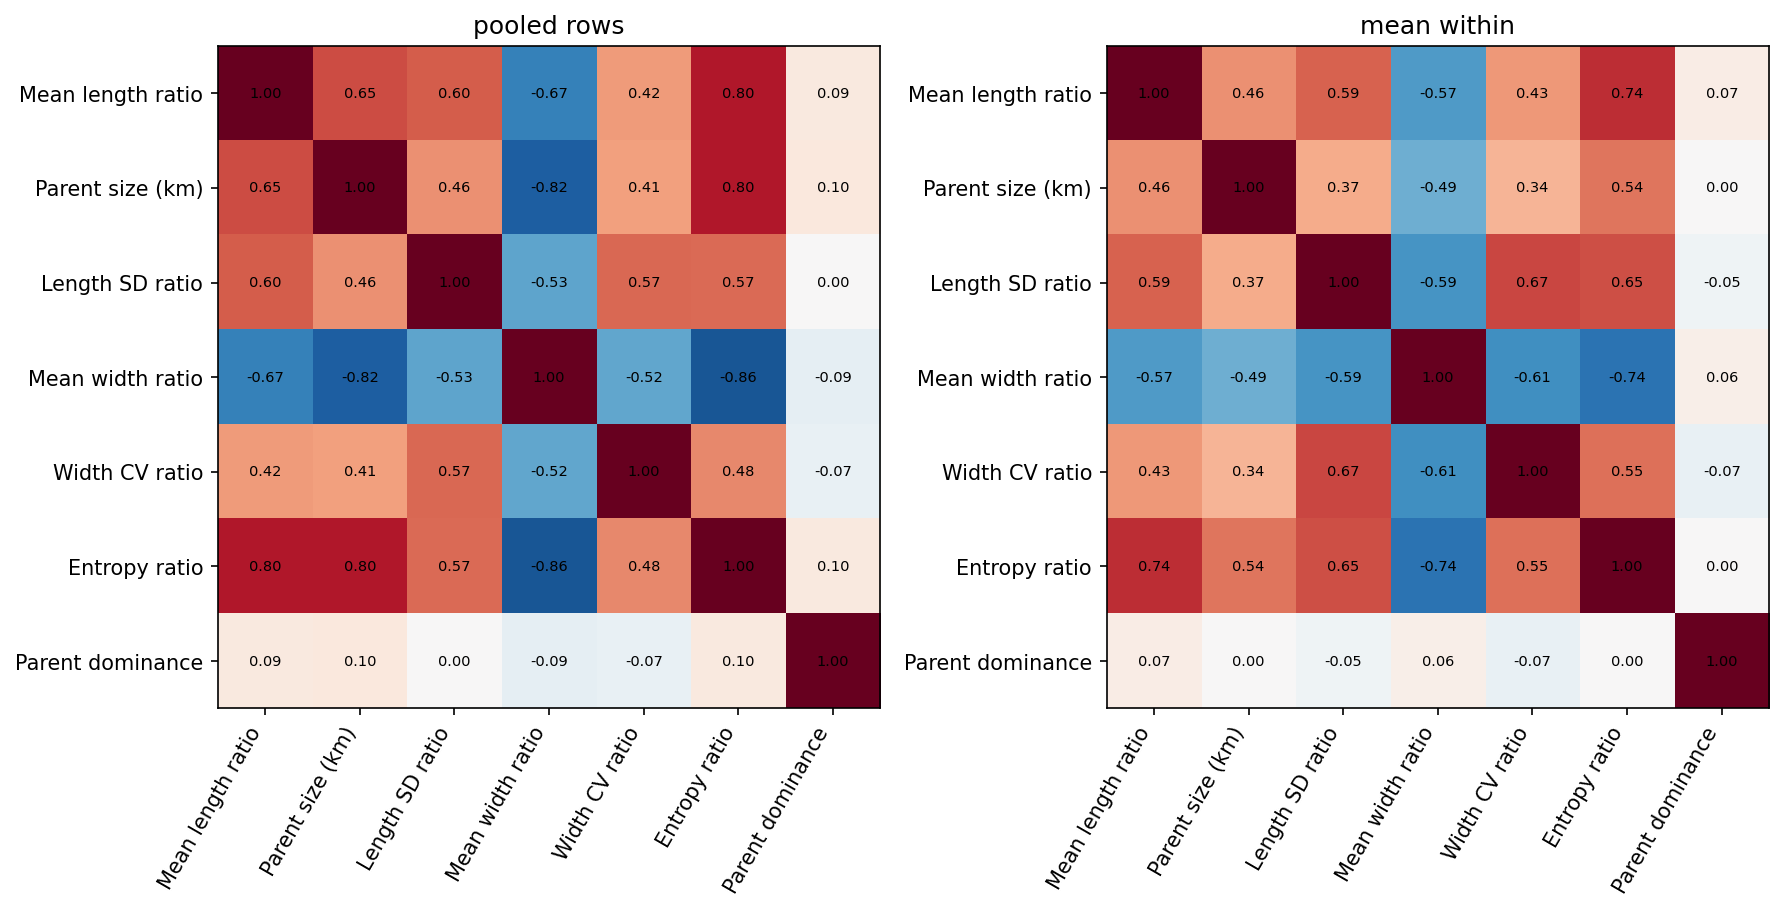

## Summary exclusions: 54 and 37 / CB001_bubble_3

**No sensitivity refits were performed.** Every view reuses the same reconstructed forests and predictions; the frozen predictor set and settings remain unchanged. Excluding 54 from summaries does not remove it from other networks’ training folds. Similarly, removing the extreme comparison from scoring does not remove its training influence on other held-network fits. Its own prediction already comes from a forest trained without all of network 37. Training influence requires a separately authorized refit study.

Permutation exclusions retain the original full-network donor pool and remove rows only from score summaries; this isolates summary sensitivity without changing the perturbation experiment. SHAP and correlations filter summary rows. ALE retains common baseline bin edges and filters local differences, so remaining local-effect summaries can be compared on common intervals. The four views are all, without 54, without the extreme comparison, and without both; each view rebalances remaining networks equally and uses its own response variance for R².

In [8]:
table = pd.read_csv(OUT / 'scores_summary_exclusions.csv')
display(table)

view,n,networks,relative_error_pct,mae,rmse,r2
all,2170,15,63.74,2.822,7.121,0.6145
without54_summary,2089,14,60.04,2.84,7.255,0.6221
without_extreme_summary,2169,15,63.73,2.761,5.316,0.7134
without_both_summary,2088,14,60.04,2.775,5.345,0.7252


In [9]:
table = pd.read_csv(OUT / 'shap_summary.csv')
table = table[['view', 'feature', 'mean_abs_shap_minutes', 'direction_positive', 'direction_negative']]
display(table)

view,feature,mean_abs_shap_minutes,direction_positive,direction_negative
all,B_parent_dominance_mean,0.1045,3,12
all,domain_size,5.389,0,15
all,log1p__B_ratio_route_entropy,0.5423,15,0
all,log1p__B_ratio_route_length_mean,0.699,15,0
all,log1p__B_ratio_route_length_sd,0.137,14,1
all,log1p__B_ratio_width_cv,0.08357,1,14
all,log1p__B_ratio_width_mean,6.543,0,15
without54_summary,B_parent_dominance_mean,0.1068,2,12
without54_summary,domain_size,5.514,0,14
without54_summary,log1p__B_ratio_route_entropy,0.5489,14,0


In [ ]:
display(pd.read_csv(OUT/'permutation_summary.csv'))
display(pd.read_csv(OUT/'response_correlation_summary.csv'))
display(pd.read_parquet(OUT/'shap_values.parquet').query("example == '37' and state == 'CB001_bubble_3'"))

## Reproduction and artifacts

Run `run.py` then `report.py` in `RAPID/investigations/hydrograph_frozen_interpretation_20261019/`. The run requires the original NumPy 1.26.4 / sklearn 1.8.0 environment and SHAP 0.46.0. On this workstation:

```sh
MPLCONFIGDIR=/private/tmp/river_frozen_mpl /opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python RAPID/investigations/hydrograph_frozen_interpretation_20261019/run.py --shap-path /private/tmp/river-shap-deps --jobs 4 --repeats 20
MPLCONFIGDIR=/private/tmp/river_frozen_mpl /opt/anaconda3/envs/river-hierarchy-rivgraph/bin/python RAPID/investigations/hydrograph_frozen_interpretation_20261019/report.py
```

Verified fold artifacts are resumable under an exact design fingerprint. Baseline files are never written. Results, full precision CSV/Parquet tables and PNG figures live in `RAPID/outputs/hydrograph_frozen_interpretation_20261019/`. This notebook embeds its figures and primary tables for review without rerunning the forests. Statistical companion models belong in a separate work area.